# 04 · Market regimes and currency factors

**Regimes.** Each trading day is described by a market state shared by all seven pairs (`fxml.regimes.state`), built only from trailing windows:

- short and long horizon volatility (5 and 63 day realized variance, averaged over pairs);
- trend strength (average ADX);
- the average correlation of the currencies' returns against the dollar over 63 days;
- the VIX.

Four clustering methods group days into regimes: k-means, Ward hierarchical clustering, a Gaussian mixture fitted by EM and DBSCAN. Regimes are numbered by average short horizon volatility on the training days, so regime 0 is always the calmest.

Two kinds of labels are used (`scripts/run_regimes.py`):

- **walk-forward**: refitted every January from 2012 on earlier days only. These are the only labels later phases may use as features;
- **full sample**: one fit on all days, used only to describe the history.

**Currency factors.** PCA of the seven currencies' daily returns against the dollar, also refitted every January.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from fxml import viz
from fxml.config import load_config

cfg = load_config()
viz.apply_style()
tables = cfg.paths.reports / "tables"
state = pd.read_parquet(cfg.paths.processed / "market_state.parquet")
selection = pd.read_csv(tables / "regimes_selection.csv")
summary = pd.read_csv(tables / "regimes_summary.csv")
transitions = pd.read_csv(tables / "regimes_transitions.csv")
ari = pd.read_csv(tables / "regimes_agreement.csv", index_col=0)
loadings = pd.read_csv(tables / "factors_loadings.csv")
explained = pd.read_csv(tables / "factors_explained.csv", index_col=0)["explained_variance"]
test_start = pd.Timestamp(cfg.walk_forward.test_start)

K = summary.query("method == 'gmm'")["regime"].nunique()
REGIME_COLORS = [viz.SEQUENTIAL_BLUE[i] for i in np.linspace(0, 6, K).round().astype(int)]
NAMES = {"kmeans": "k-means", "ward": "Ward", "gmm": "Gaussian mixture", "dbscan": "DBSCAN"}
STATE = ["vol_short", "vol_long", "trend", "correlation", "vix"]


def annual_vol(log_rv):
    """Annualised volatility in percent from a log daily realized variance."""
    return 100 * np.sqrt(np.exp(log_rv) * 252)


pd.set_option("display.precision", 3)
print(f"{state[STATE].dropna().shape[0]:,} days with a complete state; {K} regimes")

5,295 days with a complete state; 2 regimes


## The market state

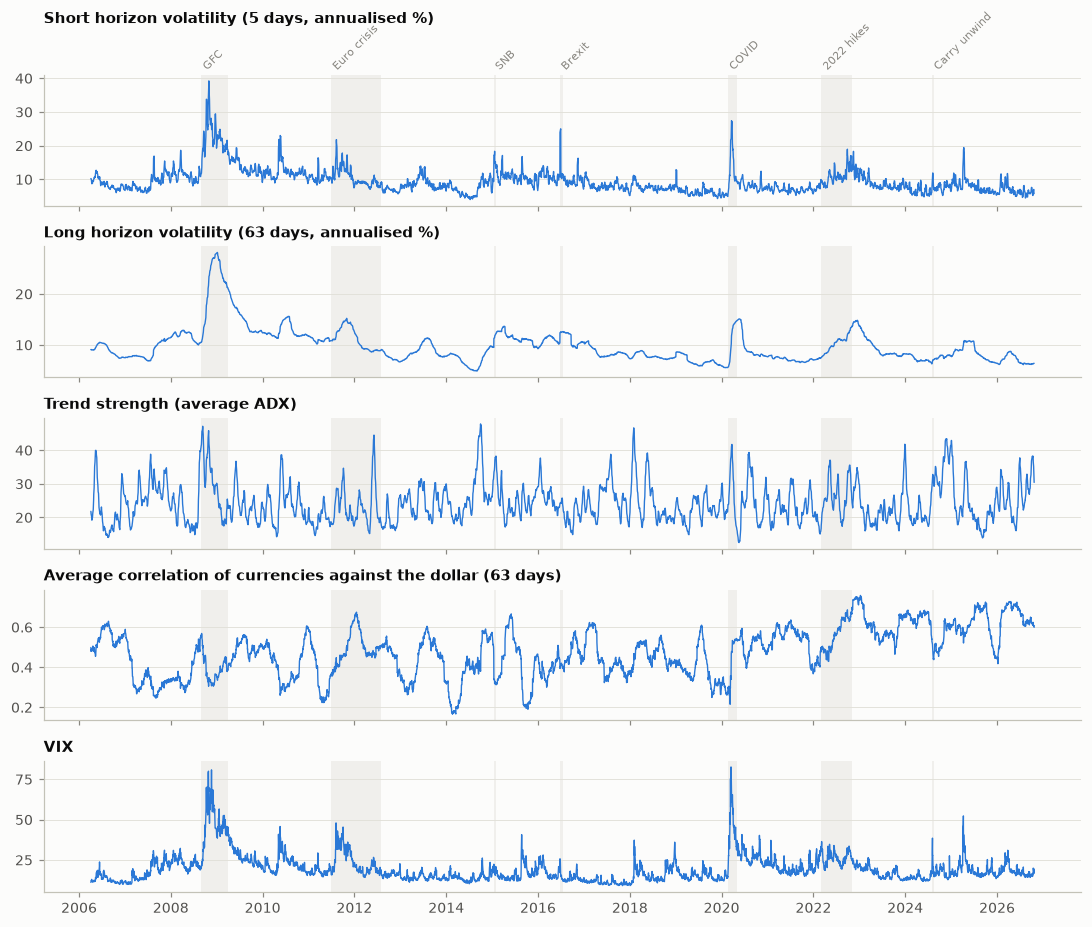

In [2]:
panels = [
    ("vol_short", "Short horizon volatility (5 days, annualised %)", annual_vol),
    ("vol_long", "Long horizon volatility (63 days, annualised %)", annual_vol),
    ("trend", "Trend strength (average ADX)", None),
    ("correlation", "Average correlation of currencies against the dollar (63 days)", None),
    ("vix", "VIX", np.exp),
]
complete = state[STATE].notna().all(axis=1)  # windows warm, every pair trading
fig, axes = plt.subplots(len(panels), 1, figsize=(10, 8.5), sharex=True)
for i, (ax, (column, title, transform)) in enumerate(zip(axes, panels)):
    viz.shade_stress(ax, label=i == 0)
    series = state.loc[complete, column]
    ax.plot(series.index, transform(series) if transform else series, color=viz.CATEGORICAL[0], lw=0.9)
    ax.set_title(title, pad=34 if i == 0 else 6)
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
viz.save(fig, "regimes_market_state")

In [3]:
state[STATE].corr()

,vol_short,vol_long,trend,correlation,vix
vol_short,1.000,0.848,0.265,-0.138,0.633
vol_long,0.848,1.000,0.008,-0.092,0.590
trend,0.265,0.008,1.000,-0.087,0.169
correlation,-0.138,-0.092,-0.087,1.000,-0.047
vix,0.633,0.590,0.169,-0.047,1.000


## How many regimes?

Chosen on the first training window only (April 2006 to December 2011). Every method and criterion votes for its best number of regimes, counting only solutions whose smallest regime holds at least 10% of the days, so each regime has enough history for a model of its own in Phase 4. All methods then use the winning number.

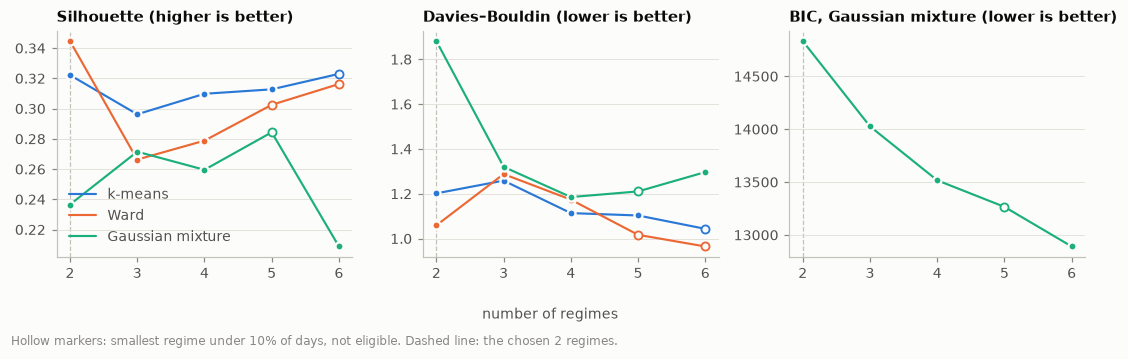

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharex=True)
criteria = [("silhouette", "Silhouette (higher is better)"),
            ("davies_bouldin", "Davies–Bouldin (lower is better)"),
            ("bic", "BIC, Gaussian mixture (lower is better)")]
for ax, (criterion, title) in zip(axes, criteria):
    for i, method in enumerate(["kmeans", "ward", "gmm"]):
        rows = selection[selection.method == method].dropna(subset=[criterion])
        if rows.empty:
            continue
        color = viz.CATEGORICAL[i]
        ax.plot(rows.k, rows[criterion], color=color, label=NAMES[method])
        ok = rows.min_share >= 0.10
        ax.scatter(rows.k[ok], rows[criterion][ok], color=color, s=28, zorder=3,
                   edgecolor=viz.SURFACE, linewidth=1.5)
        ax.scatter(rows.k[~ok], rows[criterion][~ok], facecolor=viz.SURFACE, edgecolor=color,
                   s=28, zorder=3, linewidth=1.2)
    ax.axvline(K, color=viz.BASELINE, lw=0.8, ls="--", zorder=0)
    ax.set_title(title)
    ax.set_xticks(range(2, 7))
axes[0].legend(loc="lower left")
fig.supxlabel("number of regimes", color=viz.INK_SECONDARY, fontsize=9)
fig.text(0.01, -0.06, f"Hollow markers: smallest regime under 10% of days, not eligible. "
         f"Dashed line: the chosen {K} regimes.", color=viz.INK_MUTED, fontsize=8)
fig.tight_layout()
viz.save(fig, "regimes_selection")

In [5]:
selection.pivot(index="k", columns="method", values=["silhouette", "davies_bouldin", "min_share", "votes"]).round(3)

silhouette               davies_bouldin               min_share         \
method        gmm kmeans   ward            gmm kmeans   ward       gmm kmeans   
k                                                                               
2           0.237  0.322  0.345          1.881  1.202  1.059     0.379  0.291   
3           0.272  0.296  0.266          1.320  1.259  1.288     0.168  0.203   
4           0.260  0.310  0.279          1.185  1.114  1.174     0.128  0.171   
5           0.284  0.313  0.303          1.211  1.103  1.017     0.099  0.103   
6           0.209  0.323  0.316          1.297  1.044  0.965     0.103  0.086   

              votes              
method   ward   gmm kmeans ward  
k                                
2       0.174   0.0    1.0  2.0  
3       0.174   1.0    0.0  0.0  
4       0.174   1.0    0.0  0.0  
5       0.029   0.0    1.0  0.0  
6       0.029   1.0    0.0  0.0

## Regime timeline, 2006–2026

Full sample fits, to describe the history. The line is the 5 day realized volatility averaged over pairs; shaded bands are the documented stress episodes.

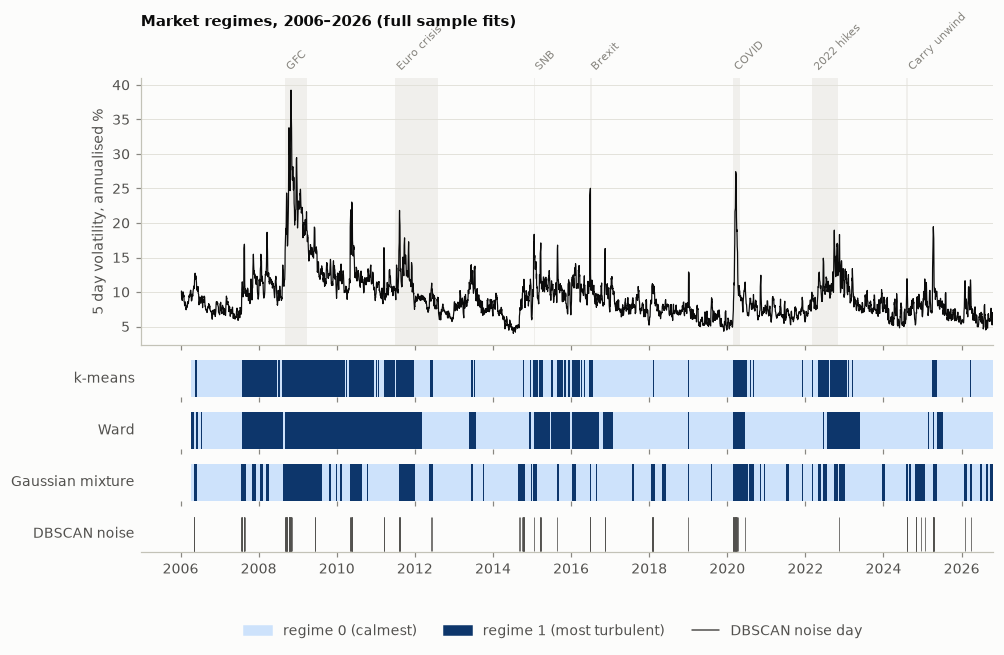

In [6]:
def regime_strip(ax, labels, name):
    labels = labels.dropna().astype(int)
    edges = labels.index.append(pd.DatetimeIndex([labels.index[-1] + pd.Timedelta(days=1)]))
    cmap = ListedColormap(REGIME_COLORS)
    norm = BoundaryNorm(np.arange(-0.5, K), K)
    ax.pcolormesh(mdates.date2num(edges), [0, 1], labels.to_numpy()[None, :], cmap=cmap,
                  norm=norm, rasterized=True)
    ax.set_yticks([])
    ax.set_ylabel(name, rotation=0, ha="right", va="center", color=viz.INK_SECONDARY)
    ax.grid(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_visible(False)


fig, axes = plt.subplots(5, 1, figsize=(10, 5.6), sharex=True,
                         gridspec_kw={"height_ratios": [4, 0.55, 0.55, 0.55, 0.55], "hspace": 0.18})
ax = axes[0]
viz.shade_stress(ax, label=True)
vol = annual_vol(state["vol_short"].dropna())
ax.plot(vol.index, vol, color=viz.INK, lw=0.8)
ax.set_title("Market regimes, 2006–2026 (full sample fits)", pad=34)
ax.set_ylabel("5 day volatility, annualised %")
for ax, method in zip(axes[1:4], ["kmeans", "ward", "gmm"]):
    regime_strip(ax, state[f"full_{method}"], NAMES[method])
ax = axes[4]
noise = state.index[state["full_dbscan"] == -1]
ax.vlines(noise, 0, 1, color=viz.INK_SECONDARY, lw=0.5)
ax.set_yticks([])
ax.set_ylabel("DBSCAN noise", rotation=0, ha="right", va="center", color=viz.INK_SECONDARY)
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
handles = [Patch(color=c, label=f"regime {r}") for r, c in enumerate(REGIME_COLORS)]
handles[0].set_label("regime 0 (calmest)")
handles[-1].set_label(f"regime {K - 1} (most turbulent)")
handles.append(Line2D([], [], color=viz.INK_SECONDARY, lw=1, label="DBSCAN noise day"))
fig.legend(handles=handles, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.05))
viz.save(fig, "regimes_timeline")

### Persistence

A spell is an unbroken run of days in one regime. `stay_probability` is the chance that tomorrow is in the same regime as today.

In [7]:
persistence = ["share_of_days", "spells", "mean_spell_days", "median_spell_days", "stay_probability"]
summary.query("method != 'dbscan'").set_index(["labels", "method", "regime"])[persistence]

share_of_days  spells  mean_spell_days  \
labels       method regime                                           
walk_forward kmeans 0               0.887      26          130.731   
                    1               0.113      25           17.400   
full_sample  kmeans 0               0.676      63           56.825   
                    1               0.324      62           27.661   
walk_forward ward   0               0.865      46           72.065   
                    1               0.135      45           11.533   
full_sample  ward   0               0.601      31          102.677   
                    1               0.399      31           68.129   
walk_forward gmm    0               0.753      86           33.581   
                    1               0.247      86           11.000   
full_sample  gmm    0               0.735      75           51.907   
                    1               0.265      75           18.693   
walk_forward hmm    0               0.639      53           46.208   
                    1               0.361      53           26.132   
full_sample  hmm    0               0.489      23          112.565   
                    1               0.511      23          117.652   

                            median_spell_days  stay_probability  
labels       method regime                                       
walk_forward kmeans 0                    21.0             0.993  
                    1                     6.0             0.943  
full_sample  kmeans 0                    13.0             0.983  
                    1                     7.0             0.964  
walk_forward ward   0                    14.0             0.986  
                    1                     4.0             0.913  
full_sample  ward   0                    14.0             0.991  
                    1                    10.0             0.985  
walk_forward gmm    0                    12.0             0.970  
                    1                     5.0             0.910  
full_sample  gmm    0                    24.0             0.981  
                    1                     7.0             0.947  
walk_forward hmm    0                    26.0             0.978  
                    1                    16.0             0.962  
full_sample  hmm    0                    95.0             0.991  
                    1                    29.0             0.992

In [8]:
# Walk-forward Gaussian mixture: probability of moving from each regime (rows) to each (columns)
transitions.query("method == 'gmm' and labels == 'walk_forward'").pivot(index="from", columns="to", values="probability")

to,0,1
from,,
0,0.97,0.03
1,0.09,0.91


## What the regimes look like, and what follows them

Walk-forward labels from 2012 only. `next_day_vol_pct` is the realized volatility of the next trading day averaged over pairs; `stress_capture` is the share of all stress episode days that fall in the regime.

In [9]:
cols = ["share_of_days", "next_day_vol_pct", "stress_share", "stress_capture",
        "mean_vol_short", "mean_trend", "mean_correlation", "mean_vix"]
summary.query("labels == 'walk_forward'").set_index(["method", "regime"])[cols]

share_of_days  next_day_vol_pct  stress_share  stress_capture  \
method regime                                                                  
kmeans  0          8.865e-01             8.610         0.072           0.582   
        1          1.135e-01            13.336         0.402           0.418   
ward    0          8.646e-01             8.507         0.089           0.706   
        1          1.354e-01            13.126         0.237           0.294   
gmm     0          7.533e-01             8.679         0.080           0.554   
        1          2.467e-01            10.872         0.198           0.446   
dbscan -1          3.607e-01             9.779         0.153           0.506   
        0          1.904e-02             9.101         0.000           0.000   
        1          5.373e-02             8.991         0.000           0.000   
        2          5.644e-01             8.943         0.095           0.489   
        3          5.216e-04            10.083         1.000           0.005   
        4          1.565e-03            13.488         0.000           0.000   
hmm     0          6.388e-01             8.693         0.091           0.535   
        1          3.612e-01            10.206         0.141           0.465   

               mean_vol_short  mean_trend  mean_correlation  mean_vix  
method regime                                                          
kmeans  0             -10.670      23.858             0.497     2.766  
        1              -9.749      28.329             0.523     3.287  
ward    0             -10.678      23.840             0.503     2.771  
        1              -9.845      27.725             0.477     3.172  
gmm     0             -10.641      22.352             0.494     2.753  
        1             -10.332      30.513             0.517     3.045  
dbscan -1             -10.504      26.333             0.500     2.891  
        0             -10.547      25.062             0.453     2.686  
        1             -10.494      23.737             0.418     2.623  
        2             -10.614      23.121             0.508     2.806  
        3              -9.991      41.029             0.468     3.067  
        4              -9.837      27.375             0.743     3.092  
hmm     0             -10.654      22.290             0.498     2.739  
        1             -10.408      28.036             0.503     2.977

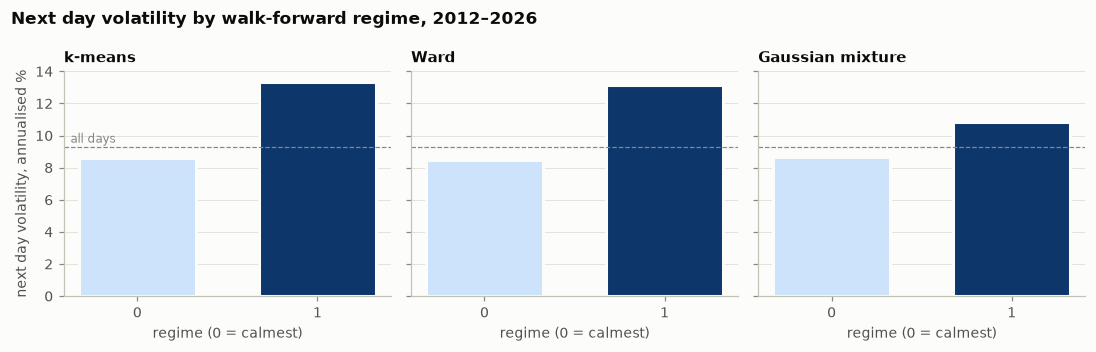

In [10]:
features = pd.read_parquet(cfg.paths.processed / "features.parquet", columns=["y_rv"])
next_rv = features["y_rv"].unstack("pair")[list(cfg.pairs)].mean(axis=1)
next_vol = 100 * np.sqrt(next_rv * 252)
test = state[state.index >= test_start]
baseline = 100 * np.sqrt(next_rv.reindex(test.index).mean() * 252)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
for ax, method in zip(axes, ["kmeans", "ward", "gmm"]):
    rows = summary.query("labels == 'walk_forward' and method == @method")
    ax.bar(rows.regime, rows.next_day_vol_pct, color=REGIME_COLORS, width=0.65,
           edgecolor=viz.SURFACE, linewidth=2)
    ax.axhline(baseline, color=viz.INK_MUTED, lw=0.8, ls="--")
    ax.set_title(NAMES[method])
    ax.set_xticks(range(K))
    ax.set_xlabel("regime (0 = calmest)")
axes[0].set_ylabel("next day volatility, annualised %")
axes[0].annotate("all days", xy=(0.02, baseline), xycoords=("axes fraction", "data"),
                 xytext=(0, 3), textcoords="offset points", ha="left", fontsize=8,
                 color=viz.INK_MUTED)
fig.suptitle("Next day volatility by walk-forward regime, 2012–2026", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
viz.save(fig, "regimes_next_day_vol")

In [11]:
# Regimes overlap: the spread of next day volatility within each walk-forward k-means regime
spread = next_vol.reindex(test.index).groupby(test["regime_kmeans"]).quantile([0.1, 0.5, 0.9])
spread.unstack().rename(columns=lambda q: f"q{int(q * 100)}")

,q10,q50,q90
regime_kmeans,,,
0.0,5.614,7.769,11.023
1.0,9.039,11.566,17.451


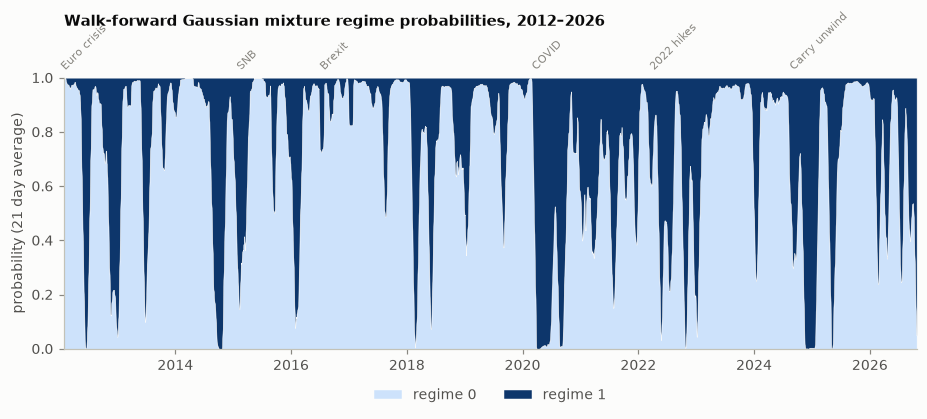

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.2))
viz.shade_stress(ax, label=True, since=test_start)
proba = test[[f"gmm_p{r}" for r in range(K)]].rolling(21).mean().dropna()
ax.stackplot(proba.index, proba.T.to_numpy(), colors=REGIME_COLORS, edgecolor=viz.SURFACE,
             linewidth=0.3, labels=[f"regime {r}" for r in range(K)])
ax.set_ylim(0, 1)
ax.set_xlim(proba.index[0], proba.index[-1])
ax.set_ylabel("probability (21 day average)")
ax.set_title("Walk-forward Gaussian mixture regime probabilities, 2012–2026", pad=34)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=K)
viz.save(fig, "regimes_probabilities")

### Agreement between methods

Adjusted Rand index of the walk-forward labels from 2012: 1 means the same grouping of days, 0 what chance would give.

In [13]:
ari

,kmeans,ward,gmm,dbscan,hmm
kmeans,1.000,0.603,0.251,0.049,0.133
ward,0.603,1.000,0.203,0.019,0.106
gmm,0.251,0.203,1.000,0.137,0.382
dbscan,0.049,0.019,0.137,1.000,0.085
hmm,0.133,0.106,0.382,0.085,1.000


### DBSCAN

Share of days DBSCAN calls noise, each year.

In [14]:
pd.DataFrame({
    "walk_forward": (state["regime_dbscan"] == -1).groupby(state.index.year).mean(),
    "full_sample": (state["full_dbscan"] == -1).groupby(state.index.year).mean(),
}).rename_axis("year").T

year,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
walk_forward,0.045,0.072,0.152,0.031,0.043,0.054,0.533,0.202,0.76,0.386,...,0.371,0.197,0.314,0.521,0.363,0.538,0.147,0.323,0.216,0.357
full_sample,0.021,0.048,0.137,0.012,0.039,0.035,0.008,0.000,0.05,0.027,...,0.000,0.035,0.004,0.116,0.000,0.004,0.000,0.046,0.039,0.010


## Currency factors

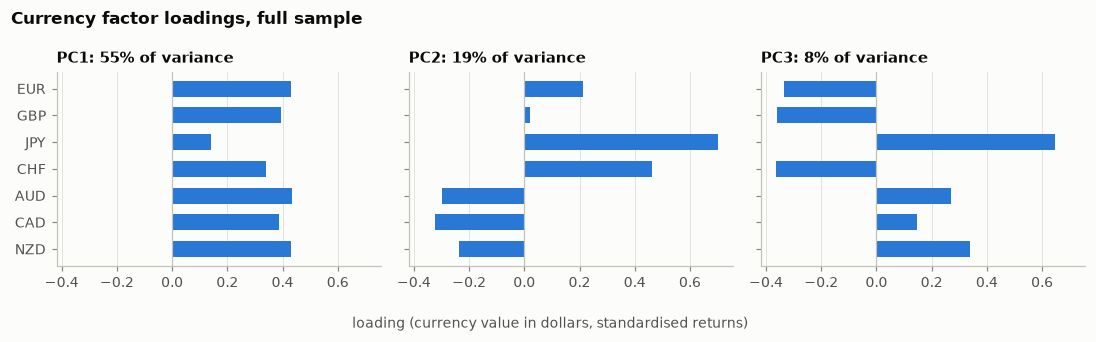

In [15]:
order = [p[3:] if p.startswith("USD") else p[:3] for p in cfg.pairs]
full = loadings[loadings.fit == "full sample"].set_index("currency").loc[order]
titles = {"pc1": "PC1", "pc2": "PC2", "pc3": "PC3"}
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True, sharex=True)
for ax, pc in zip(axes, ["pc1", "pc2", "pc3"]):
    ax.barh(order, full[pc], color=viz.CATEGORICAL[0], height=0.6)
    ax.axvline(0, color=viz.BASELINE, lw=0.8)
    ax.set_title(f"{titles[pc]}: {explained[pc]:.0%} of variance")
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
fig.supxlabel("loading (currency value in dollars, standardised returns)", color=viz.INK_SECONDARY,
              fontsize=9)
fig.suptitle("Currency factor loadings, full sample", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
viz.save(fig, "factors_loadings")

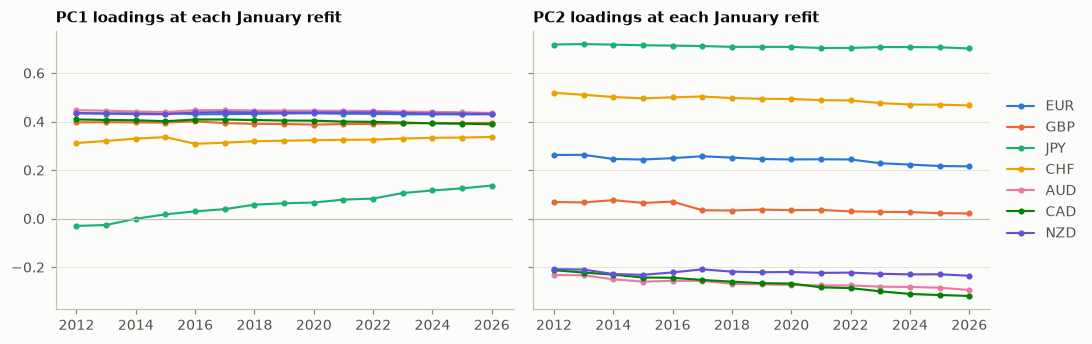

In [16]:
yearly = loadings[loadings.fit != "full sample"].assign(fit=lambda d: pd.to_datetime(d.fit).dt.year)
colors = dict(zip(order, viz.CATEGORICAL))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, pc in zip(axes, ["pc1", "pc2"]):
    for currency in order:
        rows = yearly[yearly.currency == currency]
        ax.plot(rows.fit, rows[pc], color=colors[currency], marker="o", ms=3, label=currency)
    ax.axhline(0, color=viz.BASELINE, lw=0.8)
    ax.set_title(f"{titles[pc]} loadings at each January refit")
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
viz.save(fig, "factors_loadings_stability")

In [17]:
# Does PC1 track the dollar? Correlation of daily factor returns with the broad dollar index
dollar = pd.read_parquet(cfg.paths.processed / "features.parquet", columns=["dollar_ret_1"])
dollar = dollar.xs(cfg.pairs[0], level="pair")["dollar_ret_1"]
walk = state.loc[state.index >= test_start, ["pc1", "pc2", "pc3"]]
walk.corrwith(dollar.reindex(walk.index)).rename("correlation with broad dollar return")

pc1   -0.733
pc2   -0.234
pc3   -0.074
Name: correlation with broad dollar return, dtype: float64

## Findings

**The market state has no sharp clusters, so the number of regimes is fragile.** Silhouette stays between 0.21 and 0.34 for every method and number of regimes, and BIC keeps falling as regimes are added. The vote picks 2 regimes (3 of 7 votes: Ward's silhouette and Davies–Bouldin plus the k-means silhouette). Before the ADX warm-up fix changed a few months of 2006 inputs the same vote picked 4, so the choice should be read as "a calm and a turbulent state" rather than a precise count. Volatility dominates the state (short and long horizon volatility and the VIX correlate 0.6 to 0.85 with each other) while trend strength and correlation vary almost independently of it.

**Regimes are persistent.** Out of sample the chance of staying in the same regime the next day is 0.91 to 0.99. Calm spells last 34 to 131 days on average (medians 12 to 21) and turbulent spells 11 to 17 days (medians 4 to 6).

**Walk-forward regimes separate next day volatility.** In the calm regime next day volatility averages 8.5% to 8.7% a year for all three methods. In the turbulent regime it is 13.3% for k-means, 13.1% for Ward and 10.9% for the Gaussian mixture, whose turbulent regime is defined as much by strong trends (average ADX 30.5 against 22.4) as by volatility. The regimes overlap: the 90th percentile of calm k-means days (11.0%) is above the 10th percentile of turbulent ones (9.0%). A regime label is context for a forecast, not a forecast.

**Crises line up with the turbulent regime.** In the full sample fits the turbulent regime covers late 2007 to 2011, the 2015–16 franc and Brexit period, COVID and the 2022 hikes. Out of sample the turbulent k-means regime holds 11% of days since 2012, and 40% of them fall inside a documented stress episode against 7% of calm days.

**k-means and Ward agree; the Gaussian mixture differs.** The adjusted Rand index between walk-forward labels is 0.60 for k-means against Ward and only 0.20 to 0.25 for either against the Gaussian mixture.

**DBSCAN finds shocks only in hindsight.** Fitted on the full sample its noise days gather in 2008 (14% of that year) and around the COVID crash (12% of 2020). Walk-forward it calls 15% to 76% of each year's days noise: any day unlike the training years counts, including calm 2014 when volatility fell below anything seen before. It describes history well but is no use as a live signal.

**Currency factors.** PC1 (55% of variance) loads positively on every currency. It is a dollar factor: out of sample its daily returns correlate −0.73 with the broad dollar index. PC2 (19%) sets the yen and franc against the commodity currencies (AUD, CAD and NZD), a safe haven factor. PC3 (8%) is mostly the yen against the European currencies. Loadings barely move across yearly refits except that the yen has slowly joined the dollar factor (its PC1 loading went from −0.03 in 2012 to 0.14 in 2026). Currencies also move together more than before: the average correlation against the dollar has averaged 0.60 to 0.65 a year since 2023, higher than in any earlier year.

**For Phase 4.** Only walk-forward outputs may be used as features: `regime_*`, `gmm_p*` and `pc1` to `pc3` in `market_state.parquet`. Before 2012 these come from the first fit on 2006 to 2011 (flagged by `labels_in_sample`), which is safe for training rows because every test day is later. The `full_*` columns see the future. With two regimes the turbulent one still holds 11% to 25% of days, enough for a model of its own.